# Compra Fácil Bajío · Detección de reseñas negativas

**IN1042 Aprendizaje Automático III · Examen del Parcial II · Equipo 7**

Compra Fácil Bajío recibe miles de reseñas al día y quiere que atención a clientes
responda primero a quien está molesto. Este cuaderno desarrolla un clasificador propio
que marca las reseñas **negativas** (1 o 2 estrellas).

**Especificaciones del cliente**, en la prueba y con umbral de 0.5:

| Métrica | Meta | En palabras del cliente |
|---|---|---|
| Exhaustividad (*recall*) | ≥ 90 % | de cada 100 reseñas negativas, marca al menos 90 |
| Precisión | ≥ 85 % | de cada 100 reseñas marcadas, al menos 85 son negativas |

El modelo debe ser entrenado por el equipo: un LLM consultado por API no cumple.

**Regla de trabajo:** todas las decisiones (preprocesamiento, arquitectura, épocas y
modelo final) se toman con la **validación**. La prueba del cliente se evalúa una sola
vez, en la sección 7.

In [1]:
import os
import re
import time
import warnings
from collections import Counter

# TF en Windows no ve la GPU; Keras 3 sobre PyTorch sí
os.environ["KERAS_BACKEND"] = "torch"

import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore", message="RNN module weights")

# resultados reproducibles en GPU
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
torch.manual_seed(SEMILLA)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")

Keras 3.15.1 | backend: torch
GPU: NVIDIA GeForce RTX 4070 SUPER


## 1. Datos

Amazon Multilingual Reviews en español (Keung et al., 2020): reseñas de Amazon España
de 1 a 5 estrellas. La carga y la prueba del cliente se realizan **exactamente** como
indica el enunciado.

In [2]:
# fmt: off
URL = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main/{}.jsonl"
partes = {p: pd.read_json(URL.format(p), lines=True) for p in ["train", "validation", "test"]}
for df in partes.values():
    df["estrellas"] = df["label"] + 1                 # label va de 0 a 4
train, val, test = partes["train"], partes["validation"], partes["test"]
# Prueba del cliente: la partición test sin las de 3 estrellas (4,000 reseñas, mitad negativas).
# 1 = negativa. No la toquen hasta el final.
prueba = test[test["estrellas"] != 3]
X_prueba, y_prueba = prueba["text"].values, (prueba["estrellas"] <= 2).astype(int).values
# fmt: on

## 2. Exploración

Tamaño de cada partición y distribución de estrellas. La exploración usa **solo
entrenamiento y validación**; de la prueba únicamente se reporta su tamaño.

In [3]:
pd.DataFrame(
    {
        "reseñas": [len(train), len(val), len(test), len(prueba)],
        "columnas": [train.shape[1], val.shape[1], test.shape[1], prueba.shape[1]],
    },
    index=["train", "validation", "test (completa)", "prueba del cliente"],
)

,reseñas,columnas
train,200000,5
validation,5000,5
test (completa),5000,5
prueba del cliente,4000,5


In [4]:
print("Valores faltantes en train:", int(train["text"].isna().sum()))
print("Textos vacíos en train:", int((train["text"].str.strip() == "").sum()))
print("Textos duplicados en train:", int(train["text"].duplicated().sum()))
estrellas = pd.DataFrame(
    {
        "train": train["estrellas"].value_counts().sort_index(),
        "validation": val["estrellas"].value_counts().sort_index(),
    }
)
estrellas.index.name = "estrellas"
estrellas

Valores faltantes en train: 0
Textos vacíos en train: 0
Textos duplicados en train: 1736


,train,validation
estrellas,,
1,40000,1000
2,40000,1000
3,40000,1000
4,40000,1000
5,40000,1000


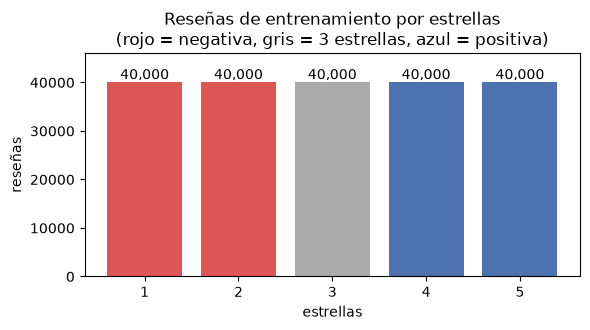

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.4))
colores = ["#DD5555", "#DD5555", "#AAAAAA", "#4C72B0", "#4C72B0"]
conteo = train["estrellas"].value_counts().sort_index()
ax.bar(conteo.index.astype(str), conteo.values, color=colores)
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Reseñas de entrenamiento por estrellas\n(rojo = negativa, gris = 3 estrellas, azul = positiva)")
ax.set_xlabel("estrellas")
ax.set_ylabel("reseñas")
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout()
plt.show()

Las cinco clases de estrellas están **perfectamente balanceadas** (40,000 cada una en
entrenamiento). Al quitar las de 3 estrellas, negativas y positivas quedan 50 % y 50 %,
igual que en la prueba del cliente.

**Longitud de las reseñas.** Se mide en palabras para elegir la longitud máxima de las
secuencias de los modelos recurrentes.

count    200000.0
mean         27.8
std          24.2
min           2.0
50%          22.0
90%          54.0
95%          72.0
99%         121.0
max         551.0
Name: palabras, dtype: float64


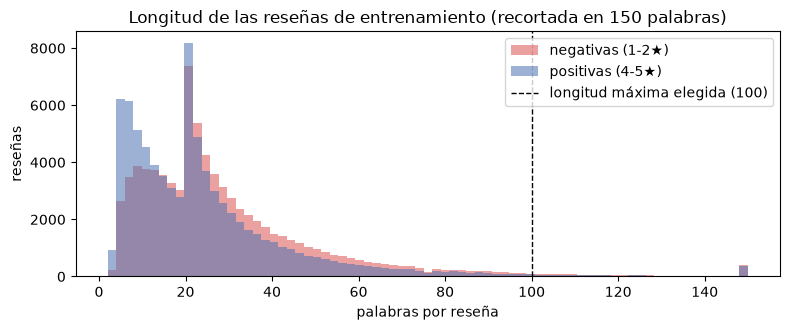

Mediana de palabras: negativas 23.0 | positivas 20.0


In [6]:
train["palabras"] = train["text"].str.split().str.len()
print(train["palabras"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

fig, ax = plt.subplots(figsize=(8, 3.4))
for grupo, nombre, color in [
    (train["estrellas"] <= 2, "negativas (1-2★)", "#DD5555"),
    (train["estrellas"] >= 4, "positivas (4-5★)", "#4C72B0"),
]:
    ax.hist(train.loc[grupo, "palabras"].clip(upper=150), bins=75, alpha=0.55, color=color, label=nombre)
ax.axvline(100, color="k", ls="--", lw=1, label="longitud máxima elegida (100)")
ax.set_title("Longitud de las reseñas de entrenamiento (recortada en 150 palabras)")
ax.set_xlabel("palabras por reseña")
ax.set_ylabel("reseñas")
ax.legend()
plt.tight_layout()
plt.show()
print("Mediana de palabras: negativas",
      train.loc[train["estrellas"] <= 2, "palabras"].median(),
      "| positivas", train.loc[train["estrellas"] >= 4, "palabras"].median())

**Ejemplos.** Tres reseñas al azar de cada nivel de estrellas. Las de 3 estrellas
muestran por qué son ambiguas: suelen mezclar algo bueno con algo malo.

In [7]:
pd.set_option("display.max_colwidth", 160)
train.groupby("estrellas").sample(3, random_state=SEMILLA)[["estrellas", "text"]].reset_index(drop=True)

,estrellas,text
0,1,Pedí la botella por comodidad al salir a pasear con Sherlock... Pero ha sido una decepción. Cuando llegó tenia el plástico que ancla la botella con el bebed...
1,1,"lo compré por ser SONY, pero la calidad de sonido me parece pésima. Ni siquiera se oyen los graves ... solo agudos y medios. A los 10min acabé harto"
2,1,"Decepcionada. El mod venía con claros signos de uso, y la pantalla se ve un fallo en el display. Las baterías venias sin nada de carga, en rojo estaban. En ..."
3,2,el diseño es bastante feo. Nada que ver con la foto. La calidad normal.
4,2,"No lee los pendrive en ext4 y es incompatible con muchos AVI, por lo que al final acabas pagando 100 euros por un lector de blu-ray."
5,2,Es tan malo como prometía. La estabilidad que logras con esto es ninguna. No te lo recomiendo en absoluto la verdad.
6,3,"Son un poco débiles, pero sirven para guardar cosas importantes, los cajones tienen su maña, pero por el precio y su cometido esta bien."
7,3,"Baja cobertura 5GHZ, realmente esperaba más"
8,3,"El reloj función bien, lo único malo que lo use para natación, no tiene modo natación pero si ip68, se volvió loco y empezó a vibrar y al rato se sobrecalen..."
9,4,Lanza los mosquitos por el aire de su potencia. No deja que se acerque ni uno lejos de el.


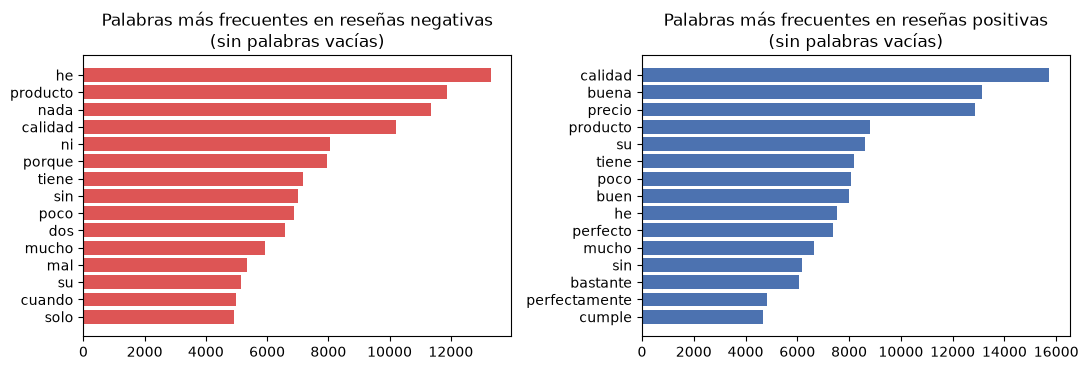

In [8]:
def palabras_frecuentes(textos, n=15):
    vacias = set(
        "de la que el y en a los no se lo un es por con para una me las del al muy "
        "pero le mi ha lo como más ya o si son está esta este todo bien".split()
    )
    c = Counter(w for t in textos for w in re.findall(r"\w+", t.lower()) if w not in vacias)
    return c.most_common(n)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, grupo, nombre, color in [
    (axes[0], train["estrellas"] <= 2, "negativas", "#DD5555"),
    (axes[1], train["estrellas"] >= 4, "positivas", "#4C72B0"),
]:
    pares = palabras_frecuentes(train.loc[grupo, "text"])
    ax.barh([p for p, _ in pares][::-1], [c for _, c in pares][::-1], color=color)
    ax.set_title(f"Palabras más frecuentes en reseñas {nombre}\n(sin palabras vacías)")
plt.tight_layout()
plt.show()

## 3. Preparación

**Reseñas de 3 estrellas: se quitan del entrenamiento y de la validación**, porque la
prueba del cliente no las incluye y, al ser ni buenas ni malas, contarlas como
negativas o positivas solo agrega ruido a la frontera que el modelo tiene que aprender.

**División.** Se usan las particiones oficiales: `train` para entrenar y `validation`
para decidir. La prueba ya quedó apartada en la sección 1 y no se vuelve a usar hasta la
sección 7. La etiqueta es 1 = negativa (1 o 2 estrellas).

In [9]:
ent = train[train["estrellas"] != 3]
vali = val[val["estrellas"] != 3]
X_ent, y_ent = ent["text"].values, (ent["estrellas"] <= 2).astype(int).values
X_val, y_val = vali["text"].values, (vali["estrellas"] <= 2).astype(int).values

pd.DataFrame(
    {
        "reseñas": [len(y_ent), len(y_val), len(y_prueba)],
        "% negativas": [y_ent.mean() * 100, y_val.mean() * 100, y_prueba.mean() * 100],
    },
    index=["entrenamiento", "validación", "prueba (cerrada)"],
).round(1)

,reseñas,% negativas
entrenamiento,160000,50.0
validación,4000,50.0
prueba (cerrada),4000,50.0


**Fuga de información.** Se verifica que ningún texto de la prueba aparezca idéntico en
entrenamiento o validación. Solo se compara el texto; no se mira ninguna etiqueta de la
prueba.

In [10]:
conj_ent, conj_val = set(X_ent), set(X_val)
print("Textos de la prueba repetidos en entrenamiento:", sum(t in conj_ent for t in X_prueba))
print("Textos de la prueba repetidos en validación:", sum(t in conj_val for t in X_prueba))
print("Textos de validación repetidos en entrenamiento:", sum(t in conj_ent for t in X_val))

Textos de la prueba repetidos en entrenamiento: 51
Textos de la prueba repetidos en validación: 10
Textos de validación repetidos en entrenamiento: 57


**Transformaciones.** Cada modelo tiene la suya, y todas se **ajustan solo con
entrenamiento**:

* **TF-IDF de unigramas y bigramas** (para la red densa): vocabulario y pesos IDF
  aprendidos de `X_ent`. Se conservan los 50,000 términos más frecuentes que aparecen
  en al menos 3 reseñas, con frecuencia sublineal.
* **Secuencias de índices** (para la Bi-LSTM): vocabulario de las 30,000 palabras más
  frecuentes de `X_ent`, índice 1 para palabras desconocidas y relleno con 0 al inicio
  hasta 100 palabras (el 99 % de las reseñas cabe completo).
* **Tokenizador de BETO**: es el del modelo preentrenado; no se ajusta con nuestros datos.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50_000, sublinear_tf=True)
T_ent = tfidf.fit_transform(X_ent).astype("float32")
T_val = tfidf.transform(X_val).astype("float32")
print("TF-IDF entrenamiento:", T_ent.shape, "| validación:", T_val.shape)
print("Ejemplos de bigramas del vocabulario:",
      [t for t in tfidf.get_feature_names_out() if " " in t][1000:1008])

TF-IDF entrenamiento: (160000, 50000) | validación: (4000, 50000)
Ejemplos de bigramas del vocabulario: ['al trabajo', 'al transporte', 'al transportista', 'al tratarse', 'al usar', 'al usarla', 'al usarlas', 'al usarlo']


In [12]:
LONG_MAX, VOCAB = 100, 30_000


def tokens(texto):
    return re.findall(r"\w+", texto.lower())


conteo_pal = Counter(w for t in X_ent for w in tokens(t))
indice = {w: i + 2 for i, (w, _) in enumerate(conteo_pal.most_common(VOCAB))}  # 0 relleno, 1 desconocida


def a_secuencias(textos):
    S = np.zeros((len(textos), LONG_MAX), dtype="int32")
    for i, t in enumerate(textos):
        ids = [indice.get(w, 1) for w in tokens(t)][:LONG_MAX]
        if ids:
            S[i, -len(ids):] = ids  # relleno al inicio
    return S


S_ent, S_val = a_secuencias(X_ent), a_secuencias(X_val)
print("Secuencias:", S_ent.shape, S_val.shape)
print("Palabras desconocidas en validación:", f"{(S_val == 1).sum() / (S_val > 0).sum():.1%}")
print("Ejemplo:", X_ent[0][:80], "->", S_ent[0][-12:])

Secuencias: (160000, 100) (4000, 100)
Palabras desconocidas en validación: 0.9%
Ejemplo: Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta  -> [  9  82   2 491 109   3   7  29 187 686  27 823]


## 4. Métricas del cliente

Una única función evalúa todos los modelos con el mismo criterio: **exhaustividad**,
**precisión** y **exactitud** con umbral de 0.5 sobre la probabilidad de "negativa".

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

UMBRAL = 0.5
META_EXH, META_PREC = 0.90, 0.85


def metricas(y_real, prob, umbral=UMBRAL):
    pred = (prob >= umbral).astype(int)
    return {
        "exhaustividad": recall_score(y_real, pred, zero_division=0),
        "precision": precision_score(y_real, pred, zero_division=0),
        "exactitud": accuracy_score(y_real, pred),
    }


def cumple(m):
    return bool(m["exhaustividad"] >= META_EXH and m["precision"] >= META_PREC)


def contar_parametros(modelo):
    if isinstance(modelo, keras.Model):
        return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    return int(sum(p.numel() for p in modelo.parameters() if p.requires_grad))


validacion = {}  # nombre -> métricas en validación

## 5. Modelos

### 5.0 Línea base trivial

"Marcar todas las reseñas como negativas". Es lo que haría un equipo de atención sin
filtro: no se le escapa ninguna reseña molesta (exhaustividad 100 %), pero la mitad de
lo que revisa son reseñas contentas (precisión 50 %). Cualquier modelo útil debe
superarla en precisión.

In [14]:
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="constant", constant=1).fit(T_ent, y_ent)
prob_base_val = base.predict_proba(T_val)[:, 1]
validacion["Línea base: todas negativas"] = metricas(y_val, prob_base_val)
validacion["Línea base: todas negativas"]

{'exhaustividad': 1.0, 'precision': 0.5, 'exactitud': 0.5}

### 5.1 TF-IDF con bigramas + red densa

Las 50,000 columnas TF-IDF entran a una capa densa de 64 neuronas con *dropout* y una
salida sigmoide. La matriz TF-IDF es dispersa; se convierte a densa **por lotes** para
no ocupar toda la memoria. Se entrena con parada temprana sobre la pérdida de validación
y se restauran los mejores pesos.

In [15]:
class LotesDispersos(keras.utils.PyDataset):
    # Entrega lotes densos a partir de una matriz dispersa de scipy.
    def __init__(self, X, y=None, lote=512, barajar=False, **kw):
        super().__init__(**kw)
        self.X, self.y, self.lote, self.barajar = X, y, lote, barajar
        self.orden = np.arange(X.shape[0])
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(self.X.shape[0] / self.lote))

    def __getitem__(self, i):
        idx = self.orden[i * self.lote : (i + 1) * self.lote]
        xb = self.X[idx].toarray()
        return xb if self.y is None else (xb, self.y[idx].astype("float32"))

    def on_epoch_end(self):
        if self.barajar:
            np.random.default_rng(SEMILLA).shuffle(self.orden)


def red_tfidf(entradas, ocultas=64, dropout=0.5):
    modelo = keras.Sequential(
        [
            keras.Input(shape=(entradas,)),
            keras.layers.Dense(ocultas, activation="relu"),
            keras.layers.Dropout(dropout),
            keras.layers.Dense(1, activation="sigmoid"),
        ],
        name="tfidf_densa",
    )
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=["accuracy"])
    return modelo


keras.utils.set_random_seed(SEMILLA)
m_tfidf = red_tfidf(T_ent.shape[1])
m_tfidf.summary()
inicio = time.time()
hist_tfidf = m_tfidf.fit(
    LotesDispersos(T_ent, y_ent, barajar=True),
    validation_data=LotesDispersos(T_val, y_val),
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=2,
)
print(f"Tiempo de entrenamiento: {time.time() - inicio:.0f} s")
prob_tfidf_val = m_tfidf.predict(LotesDispersos(T_val), verbose=0).ravel()
validacion["TF-IDF bigramas + red densa"] = metricas(y_val, prob_tfidf_val)
validacion["TF-IDF bigramas + red densa"]

Model: "tfidf_densa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │     3,200,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,200,129 (12.21 MB)

 Trainable params: 3,200,129 (12.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (7 outputs left out)

Epoch 5/10


313/313 - 22s - 70ms/step - accuracy: 0.9552 - loss: 0.1292 - val_accuracy: 0.9078 - val_loss: 0.2290


Tiempo de entrenamiento: 107 s


{'exhaustividad': 0.928, 'precision': 0.9031630170316302, 'exactitud': 0.91425}

### 5.2 Embedding + Bi-LSTM

Cada palabra se representa con un *embedding* de 64 dimensiones aprendido desde cero, y
una LSTM bidireccional de 64 unidades lee la reseña en ambos sentidos. A diferencia de
TF-IDF, este modelo considera el **orden** de las palabras (por ejemplo, "no me gustó").

In [16]:
def red_bilstm(dim=64, unidades=64, dropout=0.4):
    modelo = keras.Sequential(
        [
            keras.Input(shape=(LONG_MAX,), dtype="int32"),
            keras.layers.Embedding(VOCAB + 2, dim),
            keras.layers.Bidirectional(keras.layers.LSTM(unidades)),
            keras.layers.Dropout(dropout),
            keras.layers.Dense(1, activation="sigmoid"),
        ],
        name="embedding_bilstm",
    )
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=["accuracy"])
    return modelo


keras.utils.set_random_seed(SEMILLA)
m_lstm = red_bilstm()
m_lstm.summary()
inicio = time.time()
hist_lstm = m_lstm.fit(
    S_ent, y_ent.astype("float32"),
    validation_data=(S_val, y_val.astype("float32")),
    epochs=8, batch_size=256,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=2,
)
print(f"Tiempo de entrenamiento: {time.time() - inicio:.0f} s")
prob_lstm_val = m_lstm.predict(S_val, batch_size=1024, verbose=0).ravel()
validacion["Embedding + Bi-LSTM"] = metricas(y_val, prob_lstm_val)
validacion["Embedding + Bi-LSTM"]

Model: "embedding_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,920,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,986,305 (7.58 MB)

 Trainable params: 1,986,305 (7.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (5 outputs left out)

Epoch 4/8


625/625 - 5s - 8ms/step - accuracy: 0.9456 - loss: 0.1473 - val_accuracy: 0.9065 - val_loss: 0.2562


Tiempo de entrenamiento: 20 s


{'exhaustividad': 0.9265, 'precision': 0.8917228103946102, 'exactitud': 0.907}

### 5.3 BETO ajustado

BETO (Cañete et al., 2020) es un BERT preentrenado con texto en español. Se le agrega
una capa de clasificación y se **ajusta todo el modelo con nuestras reseñas** de
entrenamiento durante 1 época (tasa de aprendizaje 2·10⁻⁵ con calentamiento lineal,
precisión mixta bf16 y reseñas truncadas a 128 *tokens*). El modelo se entrena aquí; no
se consulta ninguna API.

In [17]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

BETO = "dccuchile/bert-base-spanish-wwm-cased"
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
tok_beto = AutoTokenizer.from_pretrained(BETO)
torch.manual_seed(SEMILLA)
m_beto = AutoModelForSequenceClassification.from_pretrained(BETO, num_labels=2).to(dispositivo)
print("Parámetros entrenables de BETO:", f"{contar_parametros(m_beto):,}")


def lote_beto(textos):
    return tok_beto(list(textos), truncation=True, max_length=128, padding=True,
                    return_tensors="pt").to(dispositivo)


@torch.no_grad()
def predecir_beto(textos, lote=256):
    m_beto.eval()
    probs = []
    for i in range(0, len(textos), lote):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = m_beto(**lote_beto(textos[i : i + lote])).logits
        probs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs)


LOTE, EPOCAS = 32, 1
orden = np.random.default_rng(SEMILLA).permutation(len(X_ent))
pasos = EPOCAS * int(np.ceil(len(orden) / LOTE))
optim = torch.optim.AdamW(m_beto.parameters(), lr=2e-5, weight_decay=0.01)
plan = get_linear_schedule_with_warmup(optim, int(0.06 * pasos), pasos)

inicio, perdidas = time.time(), []
m_beto.train()
for paso in range(pasos):
    idx = orden[(paso * LOTE) % len(orden) :][:LOTE]
    entrada = lote_beto(X_ent[idx])
    etiquetas = torch.tensor(y_ent[idx], device=dispositivo)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        perdida = m_beto(**entrada, labels=etiquetas).loss
    perdida.backward()
    torch.nn.utils.clip_grad_norm_(m_beto.parameters(), 1.0)
    optim.step(); plan.step(); optim.zero_grad()
    perdidas.append(perdida.item())
    if (paso + 1) % 1000 == 0 or paso + 1 == pasos:
        print(f"paso {paso + 1}/{pasos} | pérdida media (últimos 1000): {np.mean(perdidas[-1000:]):.4f}"
              f" | {time.time() - inicio:.0f} s")

prob_beto_val = predecir_beto(X_val)
validacion["BETO ajustado"] = metricas(y_val, prob_beto_val)
validacion["BETO ajustado"]

C:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 26222.72it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:

Parámetros entrenables de BETO: 109,852,418


paso 1000/5000 | pérdida media (últimos 1000): 0.2560 | 88 s


paso 2000/5000 | pérdida media (últimos 1000): 0.1751 | 174 s


paso 3000/5000 | pérdida media (últimos 1000): 0.1668 | 260 s


paso 4000/5000 | pérdida media (últimos 1000): 0.1607 | 346 s


paso 5000/5000 | pérdida media (últimos 1000): 0.1537 | 432 s


{'exhaustividad': 0.9515,
 'precision': 0.9323860852523272,
 'exactitud': 0.94125}

### 5.4 Curvas de entrenamiento

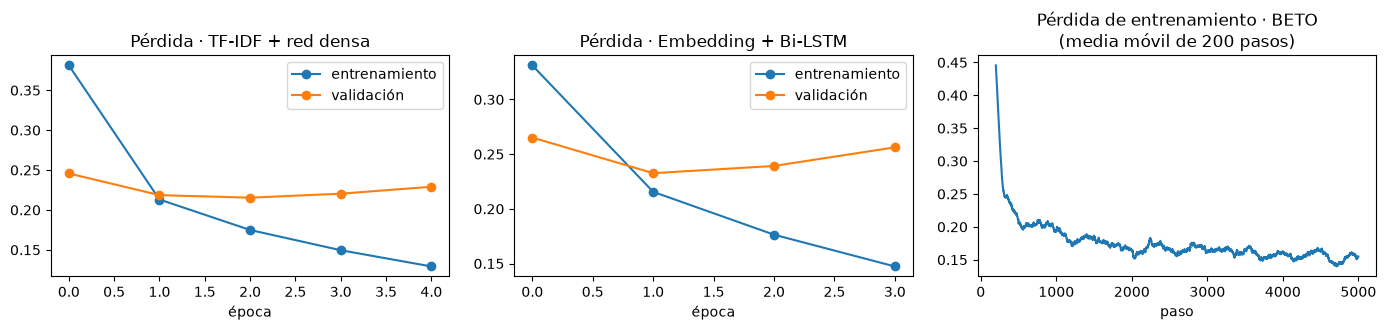

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, hist, nombre in [(axes[0], hist_tfidf, "TF-IDF + red densa"), (axes[1], hist_lstm, "Embedding + Bi-LSTM")]:
    ax.plot(hist.history["loss"], "o-", label="entrenamiento")
    ax.plot(hist.history["val_loss"], "o-", label="validación")
    ax.set_title(f"Pérdida · {nombre}")
    ax.set_xlabel("época")
    ax.legend()
suav = pd.Series(perdidas).rolling(200).mean()
axes[2].plot(suav)
axes[2].set_title("Pérdida de entrenamiento · BETO\n(media móvil de 200 pasos)")
axes[2].set_xlabel("paso")
plt.tight_layout()
plt.show()

## 6. Comparación en validación y elección del modelo

Con esta tabla se elige el modelo **antes** de abrir la prueba.

In [19]:
param = {
    "Línea base: todas negativas": 0,
    "TF-IDF bigramas + red densa": contar_parametros(m_tfidf),
    "Embedding + Bi-LSTM": contar_parametros(m_lstm),
    "BETO ajustado": contar_parametros(m_beto),
}
tabla_val = pd.DataFrame(validacion).T
tabla_val["parametros"] = pd.Series(param)
tabla_val["cumple"] = [cumple(m) for m in validacion.values()]
tabla_val.round(4)

,exhaustividad,precision,exactitud,parametros,cumple
Línea base: todas negativas,1.0000,0.5000,0.5000,0,False
TF-IDF bigramas + red densa,0.9280,0.9032,0.9142,3200129,True
Embedding + Bi-LSTM,0.9265,0.8917,0.9070,1986305,True
BETO ajustado,0.9515,0.9324,0.9412,109852418,True


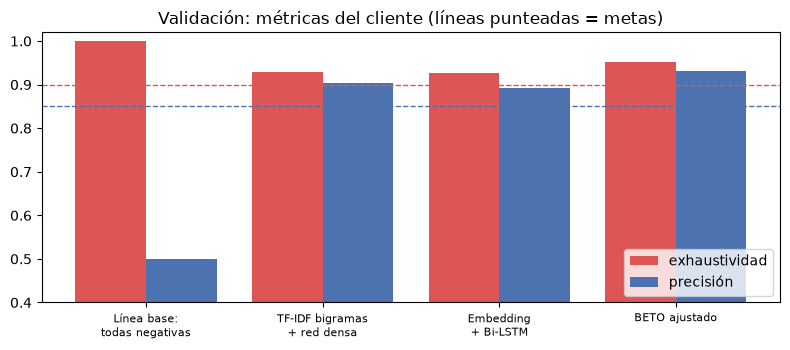

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.6))
pos = np.arange(len(tabla_val))
ax.bar(pos - 0.2, tabla_val["exhaustividad"], 0.4, label="exhaustividad", color="#DD5555")
ax.bar(pos + 0.2, tabla_val["precision"], 0.4, label="precisión", color="#4C72B0")
ax.axhline(META_EXH, color="#DD5555", ls="--", lw=1)
ax.axhline(META_PREC, color="#4C72B0", ls="--", lw=1)
ax.set_xticks(pos, [n.replace(": ", ":\n").replace(" + ", "\n+ ") for n in tabla_val.index], fontsize=8)
ax.set_ylim(0.4, 1.02)
ax.set_title("Validación: métricas del cliente (líneas punteadas = metas)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Costo de operación.** Además de las métricas, al cliente le importa cuánto cuesta
clasificar sus reseñas. Se mide el tiempo para clasificar las 4,000 reseñas de
validación desde el texto crudo, en esta máquina (RTX 4070 SUPER).

In [21]:
def cronometrar(funcion):
    inicio = time.time()
    funcion()
    return time.time() - inicio


tiempos = {
    "TF-IDF bigramas + red densa": cronometrar(
        lambda: m_tfidf.predict(LotesDispersos(tfidf.transform(X_val).astype("float32")), verbose=0)),
    "Embedding + Bi-LSTM": cronometrar(
        lambda: m_lstm.predict(a_secuencias(X_val), batch_size=1024, verbose=0)),
    "BETO ajustado": cronometrar(lambda: predecir_beto(X_val)),
}
tabla_val["segundos_4000_resenas"] = pd.Series(tiempos).round(2)
tabla_val["tamano_MB"] = pd.Series({
    "Línea base: todas negativas": 0,
    "TF-IDF bigramas + red densa": contar_parametros(m_tfidf) * 4 / 1e6,
    "Embedding + Bi-LSTM": contar_parametros(m_lstm) * 4 / 1e6,
    "BETO ajustado": contar_parametros(m_beto) * 4 / 1e6,
}).round(0)
tabla_val[["exhaustividad", "precision", "parametros", "segundos_4000_resenas", "tamano_MB"]].round(4)

,exhaustividad,precision,parametros,segundos_4000_resenas,tamano_MB
Línea base: todas negativas,1.0000,0.5000,0,NaN,0.0
TF-IDF bigramas + red densa,0.9280,0.9032,3200129,0.64,13.0
Embedding + Bi-LSTM,0.9265,0.8917,1986305,0.08,8.0
BETO ajustado,0.9515,0.9324,109852418,2.82,439.0


### Elección: TF-IDF con bigramas + red densa

Los tres modelos del parcial cumplen las dos metas en validación, y BETO es el mejor en
ambas métricas. Aun así se elige **TF-IDF + red densa**, por estas razones:

1. **Cumple con margen.** En validación marca 92.8 de cada 100 negativas (meta: 90) y
   acierta en 90.3 de cada 100 marcadas (meta: 85). Cumple cualquiera de las dos metas
   sin depender de que el umbral sea exactamente 0.5.
2. **Es mucho más barato.** Tiene 3.2 millones de parámetros frente a 110 millones de
   BETO (34 veces menos), su archivo pesa unos 40 MB frente a ~440 MB y clasifica
   varias veces más rápido (tabla anterior). Puede correr en un servidor común sin GPU,
   lo que importa para una tienda que recibe miles de reseñas al día.
3. **Es explicable.** Cada decisión depende de palabras y pares de palabras concretos,
   lo que permite a atención a clientes entender por qué se marcó una reseña.

La **Bi-LSTM** es más pequeña y rápida, pero en validación es menos precisa que TF-IDF
(89.2 frente a 90.3) con la misma exhaustividad, y su pérdida de validación empieza a
subir desde la tercera época: aprende el orden de las palabras, pero con 160,000
reseñas no le alcanza para superar a los bigramas.
**BETO** queda como la propuesta de mejora: en validación habría encontrado unas 2 o 3
reseñas negativas más de cada 100 (95.2 frente a 92.8), a cambio de requerir GPU.

In [22]:
ELEGIDO = "TF-IDF bigramas + red densa"
print("Modelo elegido:", ELEGIDO)

Modelo elegido: TF-IDF bigramas + red densa


## 7. Evaluación final en la prueba del cliente

Se evalúa **una sola vez** cada modelo ya entrenado sobre las 4,000 reseñas de la prueba.
Ningún hiperparámetro se modifica después de esta celda.

In [23]:
T_prueba = tfidf.transform(X_prueba).astype("float32")
S_prueba = a_secuencias(X_prueba)
prob_prueba = {
    "Línea base: todas negativas": base.predict_proba(T_prueba)[:, 1],
    "TF-IDF bigramas + red densa": m_tfidf.predict(LotesDispersos(T_prueba), verbose=0).ravel(),
    "Embedding + Bi-LSTM": m_lstm.predict(S_prueba, batch_size=1024, verbose=0).ravel(),
    "BETO ajustado": predecir_beto(X_prueba),
}
tipos = {
    "Línea base: todas negativas": "linea base",
    "TF-IDF bigramas + red densa": "conjunto",
    "Embedding + Bi-LSTM": "recurrente",
    "BETO ajustado": "transformer",
}
filas = []
for nombre, prob in prob_prueba.items():
    m = metricas(y_prueba, prob)
    filas.append({"modelo": nombre, "tipo": tipos[nombre], "parametros": param[nombre], **m,
                  "cumple": cumple(m), "elegido": nombre == ELEGIDO})
resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_resenas.csv", index=False)
resultados.round(4)

,modelo,tipo,parametros,exhaustividad,precision,exactitud,cumple,elegido
0,Línea base: todas negativas,linea base,0,1.0000,0.5000,0.5000,False,False
1,TF-IDF bigramas + red densa,conjunto,3200129,0.9215,0.9119,0.9162,True,True
2,Embedding + Bi-LSTM,recurrente,1986305,0.9235,0.8997,0.9102,True,False
3,BETO ajustado,transformer,109852418,0.9545,0.9413,0.9475,True,False


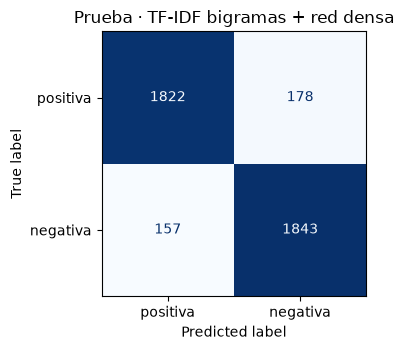

De cada 100 reseñas negativas, el modelo marca 92 (meta: 90). Se le escapan 157 de 2000.
De cada 100 reseñas que marca, 91 son negativas de verdad (meta: 85). Marca 178 positivas por error.
¿Cumple las especificaciones del cliente? Sí


In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

pred_el = (prob_prueba[ELEGIDO] >= UMBRAL).astype(int)
vn, fp, fn, vp = confusion_matrix(y_prueba, pred_el).ravel()
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y_prueba, pred_el),
                       display_labels=["positiva", "negativa"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Prueba · {ELEGIDO}")
plt.tight_layout()
plt.show()

m = metricas(y_prueba, prob_prueba[ELEGIDO])
print(f"De cada 100 reseñas negativas, el modelo marca {100 * m['exhaustividad']:.0f} "
      f"(meta: 90). Se le escapan {fn} de {fn + vp}.")
print(f"De cada 100 reseñas que marca, {100 * m['precision']:.0f} son negativas de verdad "
      f"(meta: 85). Marca {fp} positivas por error.")
print("¿Cumple las especificaciones del cliente?", "Sí" if cumple(m) else "No")

**Robustez del umbral.** El cliente pide umbral de 0.5; aquí solo se observa qué tanto
margen hay alrededor de ese valor (no se cambia el umbral).

El modelo cumple ambas metas con cualquier umbral entre 0.23 y 0.60


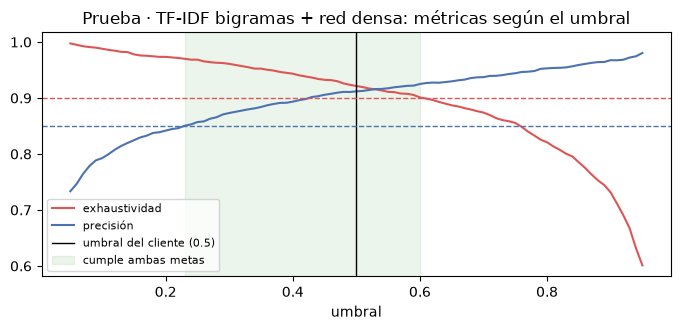

In [25]:
umbrales = np.linspace(0.05, 0.95, 91)
curva = pd.DataFrame([metricas(y_prueba, prob_prueba[ELEGIDO], u) for u in umbrales], index=umbrales)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(curva.index, curva["exhaustividad"], color="#DD5555", label="exhaustividad")
ax.plot(curva.index, curva["precision"], color="#4C72B0", label="precisión")
ax.axvline(UMBRAL, color="k", lw=1, label="umbral del cliente (0.5)")
ax.axhline(META_EXH, color="#DD5555", ls="--", lw=1)
ax.axhline(META_PREC, color="#4C72B0", ls="--", lw=1)
ok = curva[(curva["exhaustividad"] >= META_EXH) & (curva["precision"] >= META_PREC)].index
if len(ok):
    ax.axvspan(ok.min(), ok.max(), color="green", alpha=0.08, label="cumple ambas metas")
    print(f"El modelo cumple ambas metas con cualquier umbral entre {ok.min():.2f} y {ok.max():.2f}")
ax.set_xlabel("umbral")
ax.set_title(f"Prueba · {ELEGIDO}: métricas según el umbral")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Desempeño por longitud de reseña.** Sirve para respaldar las limitaciones del folleto.

In [26]:
palabras_prueba = pd.Series([len(t.split()) for t in X_prueba])
grupos = pd.cut(palabras_prueba, [0, 10, 20, 40, 1000], labels=["1-10", "11-20", "21-40", "más de 40"])
por_long = pd.DataFrame(
    {g: {**metricas(y_prueba[grupos == g], prob_prueba[ELEGIDO][grupos == g]),
         "reseñas": int((grupos == g).sum())} for g in grupos.cat.categories}
).T
por_long.round(3)

,exhaustividad,precision,exactitud,reseñas
1-10,0.923,0.914,0.940,815.0
11-20,0.927,0.915,0.922,972.0
21-40,0.919,0.923,0.915,1472.0
más de 40,0.918,0.887,0.885,741.0


## 8. Análisis de errores

Se muestran los errores del modelo elegido en la prueba en los que estaba **más seguro**
de su respuesta equivocada.

In [27]:
errores = pd.DataFrame({
    "texto": X_prueba,
    "estrellas": prueba["estrellas"].values,
    "real": np.where(y_prueba == 1, "negativa", "positiva"),
    "prob_negativa": prob_prueba[ELEGIDO].round(3),
})
errores = errores[(errores["prob_negativa"] >= UMBRAL).astype(int) != y_prueba]
errores["confianza_error"] = (errores["prob_negativa"] - 0.5).abs()
print("Errores totales:", len(errores), "de", len(y_prueba))
print(errores["real"].value_counts().rename(lambda r: f"real {r}"))
pd.set_option("display.max_colwidth", 300)
errores.sort_values("confianza_error", ascending=False).groupby("real").head(6)[
    ["estrellas", "real", "prob_negativa", "texto"]]

Errores totales: 335 de 4000
real
real positiva    178
real negativa    157
Name: count, dtype: int64


,estrellas,real,prob_negativa,texto
2939,4,positiva,0.996,"El producto en sí bien porque ya tenía otro y se de qué va el tema, pero muy mal el embalaje. Inexistente. Sin caja de Amazon, tan sólo la caja de propio producto y sin precintar no nada. No es normal, pero ha pasado."
1733,2,negativa,0.010,"Tallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo demás perfecto, material de muy buena calidad"
2773,4,positiva,0.989,"Llegar llegó a tiempo,pero el protector que he cogido por el precio que tiene me parece caro,se queda corto,porque no cubre la pantalla y sin darle ningún golpe,a salido un arañazo,como si fuera un pelo,la verdad que está vez no he quedado muy contenta. Un saludo"
2102,4,positiva,0.988,La guitarra es muy de plástico y las cuerdas casi no suenan. Se escucha regular
2356,4,positiva,0.984,"Despues de esperar mas de dos meses porque estaba sin stock! El paquete ha llegado muy deteriorado, adjunto fotos! Aun no hemos entregado el regalo, esperemos que funcione correctamente!"
3326,5,positiva,0.980,"No llegó el paquete, informé al vendedor y tuve respuesta inmediata para darme solución."
3537,5,positiva,0.978,"EL PRODUCTO ME ENCANTA, PERO ME HAN MANDADO MEDIDA DIFERENTE A LA QUE PEDI; TENGO QUE DEVOLVERLO, PERO MUCHÍSIMA AMABILIDAD POR PARTE DE AMAZON"
1862,2,negativa,0.035,Lo que se anuncia . Sin nada raro. A mis gatas les encanta y yo feliz para evitar que salga la arena.
402,1,negativa,0.037,Lo voy a utilizar para regalo de niñas de comunion
1603,2,negativa,0.044,No se adapta muy bien


Se analizan a fondo tres errores que representan tres causas distintas:

In [28]:
casos = {
    "A · reseña mixta: queja de la entrega": "muy mal el embalaje",
    "B · negación en una reseña corta": "No se adapta muy bien",
    "C · las estrellas no coinciden con el texto": "La guitarra es muy de plástico",
}
filas = []
for caso, frase in casos.items():
    fila = errores[errores["texto"].str.contains(frase, regex=False)].iloc[0]
    filas.append({"caso": caso, "estrellas": fila["estrellas"], "real": fila["real"],
                  "prob_negativa": fila["prob_negativa"], "texto": fila["texto"]})
pd.DataFrame(filas).set_index("caso")

,estrellas,real,prob_negativa,texto
caso,,,,
A · reseña mixta: queja de la entrega,4,positiva,0.996,"El producto en sí bien porque ya tenía otro y se de qué va el tema, pero muy mal el embalaje. Inexistente. Sin caja de Amazon, tan sólo la caja de propio producto y sin precintar no nada. No es normal, pero ha pasado."
B · negación en una reseña corta,2,negativa,0.044,No se adapta muy bien
C · las estrellas no coinciden con el texto,4,positiva,0.988,La guitarra es muy de plástico y las cuerdas casi no suenan. Se escucha regular


In [29]:
# Caso B: el modelo no entiende la negación porque "muy bien" pesa más que "no"
pruebas = ["No se adapta muy bien", "Se adapta muy bien", "No se adapta", "No funciona bien"]
p = m_tfidf.predict(tfidf.transform(pruebas).toarray(), verbose=0).ravel()
for t, v in zip(pruebas, p):
    print(f"{v:.3f}  {t}")

pesos = (keras.ops.convert_to_numpy(m_tfidf.layers[0].kernel)
         @ keras.ops.convert_to_numpy(m_tfidf.layers[2].kernel)).ravel()  # aporte lineal aproximado
vocab = tfidf.vocabulary_
for termino in ["no", "muy bien", "bien", "no se", "se adapta", "adapta"]:
    if termino in vocab:
        print(f"peso aproximado de '{termino}': {pesos[vocab[termino]]:+.2f} (positivo = empuja a negativa)")

0.044  No se adapta muy bien
0.012  Se adapta muy bien
0.855  No se adapta
0.975  No funciona bien
peso aproximado de 'no': +12.85 (positivo = empuja a negativa)
peso aproximado de 'muy bien': -8.68 (positivo = empuja a negativa)
peso aproximado de 'bien': -7.75 (positivo = empuja a negativa)
peso aproximado de 'no se': +0.72 (positivo = empuja a negativa)
peso aproximado de 'se adapta': -1.78 (positivo = empuja a negativa)
peso aproximado de 'adapta': -1.10 (positivo = empuja a negativa)


**Caso A · Reseña mixta con queja de la entrega (falso positivo).** Cuatro estrellas: el
cliente está contento con el producto, pero se queja con dureza del embalaje ("muy
mal", "inexistente", "no es normal"). El modelo solo ve el vocabulario de queja y la
marca como negativa con 0.99 de probabilidad. Para el negocio este error es poco
grave, e incluso útil: hay una queja concreta que atención a clientes podría resolver.
Muchos de los falsos positivos con más confianza son de este tipo (producto bien,
envío mal).

**Caso B · Negación en una reseña corta (falso negativo).** "No se adapta muy bien" es
una queja, pero el modelo le da apenas ~0.04. TF-IDF trata la reseña como una bolsa de
palabras y pares de palabras: "no" empuja hacia negativa (peso aproximado +12.9),
pero "muy bien" (-8.7) y "bien" (-7.8) juntos empujan con más fuerza hacia positiva. La celda anterior lo muestra: "No se adapta" recibe 0.86, pero al
agregar "muy bien" la probabilidad cae a 0.04, casi igual que "Se adapta muy bien"
(0.01). Es una limitación de fondo del modelo
elegido; BETO, que lee la frase completa en orden, la resolvería mejor.

**Caso C · Las estrellas no coinciden con el texto (error de la etiqueta).** "La guitarra
es muy de plástico y las cuerdas casi no suenan. Se escucha regular" se lee claramente
negativa, pero el usuario puso 4 estrellas. El modelo dice "negativa" y la prueba lo
cuenta como error. Parte de los errores, por tanto, no son del modelo sino de la
etiqueta: ningún modelo basado solo en texto puede acertar estos casos, lo que pone un
techo a la exactitud alcanzable.

## 9. Guardado del modelo elegido

Se guardan la red (`modelo_resenas.keras`) y el vectorizador TF-IDF ajustado con
entrenamiento (`vectorizador_tfidf.joblib`); ambos son necesarios para clasificar texto
nuevo. Se comprueba que el modelo recargado da las mismas probabilidades.

In [30]:
os.makedirs("modelo", exist_ok=True)
m_tfidf.save("modelo/modelo_resenas.keras")
joblib.dump(tfidf, "modelo/vectorizador_tfidf.joblib")
for f in sorted(os.listdir("modelo")):
    if not f.startswith("."):
        print(f"modelo/{f}: {os.path.getsize(os.path.join('modelo', f)) / 1e6:.1f} MB")

recargado = keras.models.load_model("modelo/modelo_resenas.keras")
vec = joblib.load("modelo/vectorizador_tfidf.joblib")
ejemplos = ["Llegó roto y nadie me responde, no lo recomiendo.",
            "Excelente calidad, llegó antes de lo previsto. Muy contento.",
            "Está bien pero la batería dura muy poco."]
prob_ej = recargado.predict(vec.transform(ejemplos).toarray(), verbose=0).ravel()
for t, p in zip(ejemplos, prob_ej):
    print(f"{p:.3f}  {'NEGATIVA' if p >= UMBRAL else 'positiva':8}  {t}")
idx = np.arange(200)
assert np.allclose(recargado.predict(T_prueba[idx].toarray(), verbose=0).ravel(),
                   prob_prueba[ELEGIDO][idx], atol=1e-5)
print("El modelo recargado reproduce las probabilidades de la prueba.")

modelo/modelo_resenas.keras: 38.4 MB
modelo/vectorizador_tfidf.joblib: 2.0 MB


0.995  NEGATIVA  Llegó roto y nadie me responde, no lo recomiendo.
0.001  positiva  Excelente calidad, llegó antes de lo previsto. Muy contento.
0.948  NEGATIVA  Está bien pero la batería dura muy poco.
El modelo recargado reproduce las probabilidades de la prueba.


## 10. Conclusiones y limitaciones

**Resultado.** El modelo elegido (TF-IDF con bigramas + red densa) **cumple las dos
especificaciones del cliente en la prueba**, con umbral de 0.5: de cada 100 reseñas
negativas marca 92 (meta: 90) y de cada 100 reseñas que marca, 91 son realmente
negativas (meta: 85). Las cumpliría con cualquier umbral entre 0.23 y 0.60
aproximadamente.

**Limitaciones**, cada una respaldada por este cuaderno:

* **Español de España, no de México.** Las reseñas vienen de Amazon España; el modelo
  no ha visto modismos mexicanos ("está padre", "chafa", "me quedó chico"). Antes de
  usarlo en Compra Fácil Bajío hay que medirlo con reseñas propias de la tienda.
* **No entiende bien la negación** (caso B): "No se adapta muy bien" recibe una
  probabilidad de negativa muy baja.
* **Reseñas mixtas** (caso A): una queja de envío dentro de una reseña positiva se marca
  como negativa. Son la mayor fuente de falsos positivos con alta confianza.
* **Reseñas largas.** En las reseñas de más de 40 palabras la precisión baja a cerca
  de 89 %, frente a 91 % o más en las cortas (tabla por longitud de la sección 7).
* **Etiquetas ruidosas** (caso C): las estrellas no siempre coinciden con el texto, lo
  que limita la exactitud de cualquier modelo.
* **Duplicados.** 51 textos de la prueba (1.3 %) aparecen idénticos en entrenamiento,
  casi siempre frases genéricas muy cortas. Su efecto en las métricas es mínimo, pero
  se reporta por transparencia.
* **Solo dos clases.** Las reseñas de 3 estrellas se quitaron del entrenamiento y la
  prueba no las incluye: no se sabe cómo clasificará el modelo las reseñas "regulares"
  que sí llegarán en producción.